# 05 · Survival analysis

**Question:** how long did chemists live, and how does that differ by era, specialty, region and sex?

**Method** (`chemkg.survival`)
- Subjects: analysable people born 1700 or later. Duration is age at death, or age in 2026 for the **likely living** (right-censored).
- Excluded: no birth year; born ≤ 1916 with no death date (a missing date, not censoring); lifespans over 110 or under 15 (date errors).
- Kaplan–Meier with log-log 95% CIs; log-rank test across eras.
- Cox PH: birth era (ref 1850–1899), primary domain (ref General), region (ref Western Europe), sex (ref male), more than one citizenship. Sparse levels are folded into "Other". PH is checked with Schoenfeld-residual tests (rank time transform). A second Cox model stratified by era drops the PH assumption for era.

**Honesty about bias.** Inclusion requires notability, which requires surviving long enough to become notable (immortal-time bias). Survival at young ages is overstated, and the era effect mixes real mortality decline with changing notability. Left truncation (when someone *enters* Wikipedia) isn't modelled. Treat this as descriptive.

In [1]:
import json, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from chemkg.data import load, analysable
from chemkg import countries
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ds = load()
P, A = ds.people, analysable(ds.people)
NAMES = countries.load_iso3().set_index("iso3").name.to_dict()
print(f"{len(P):,} people, {len(A):,} analysable; enrichment loaded: {ds.enriched}")

11,903 people, 11,860 analysable; enrichment loaded: True


In [2]:
from chemkg import survival
sf = survival.survival_frame(ds)
print(f"n = {len(sf):,}; deaths = {sf.event.sum():,}; censored = {(1 - sf.event).sum():,}")
sf.groupby("surv_era").agg(n=("qid", "size"), deaths=("event", "sum"))

n = 10,465; deaths = 7,035; censored = 3,430


,n,deaths
surv_era,,
1700–1799,508,508
1800–1849,838,838
1850–1899,1960,1960
1900–1929,2591,2555
1930–1959,3314,1136
1960+,1254,38


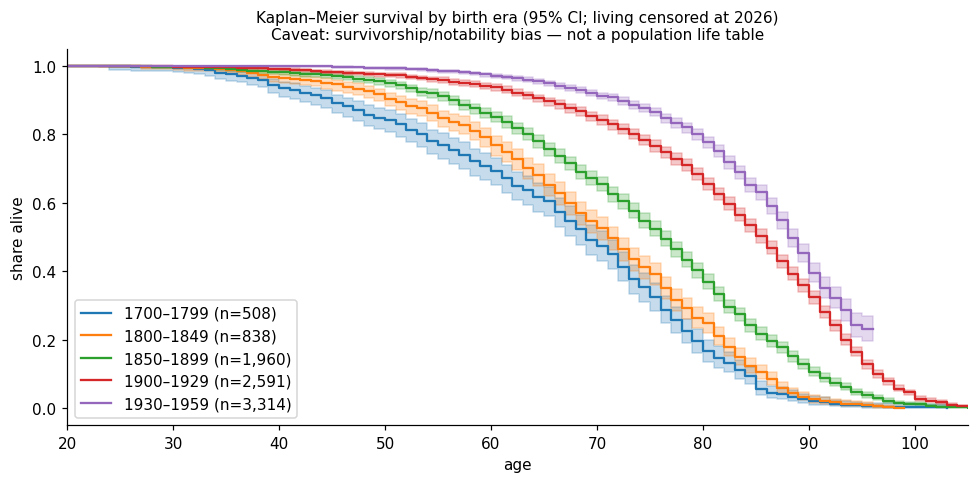

In [3]:
from lifelines import KaplanMeierFitter
fig, ax = plt.subplots(figsize=(9, 4.5))
for era in ["1700–1799", "1800–1849", "1850–1899", "1900–1929", "1930–1959"]:
    s = sf[sf.surv_era == era]
    KaplanMeierFitter(label=f"{era} (n={len(s):,})").fit(s.duration, s.event).plot_survival_function(ax=ax, ci_show=True)
ax.set_xlim(20, 105); ax.set_xlabel("age"); ax.set_ylabel("share alive")
ax.set_title("Kaplan–Meier survival by birth era (95% CI; living censored at 2026)\nCaveat: survivorship/notability bias — not a population life table", fontsize=10)
plt.tight_layout()

In [4]:
pd.DataFrame([{k: c[k] for k in ("by", "group", "n", "events", "censored", "median", "median_ci")} for c in
              survival.km_curves(sf, "surv_era") + survival.km_curves(sf, "primary_domain", min_n=150) + survival.km_curves(sf, "region", min_n=150)])

,by,group,n,events,censored,median,median_ci
0,surv_era,1930–1959,3314,1136,2178,88.0,"[88.0, 89.0]"
1,surv_era,1900–1929,2591,2555,36,86.0,"[85.0, 86.0]"
2,surv_era,1850–1899,1960,1960,0,76.0,"[76.0, 77.0]"
3,surv_era,1960+,1254,38,1216,NaN,"[None, None]"
4,surv_era,1800–1849,838,838,0,71.0,"[70.0, 72.0]"
5,surv_era,1700–1799,508,508,0,69.0,"[68.0, 71.0]"
6,primary_domain,General chemistry,6613,4776,1837,81.0,"[81.0, 81.0]"
7,primary_domain,Life & medicinal chemistry,2742,1594,1148,86.0,"[85.0, 86.0]"
8,primary_domain,Applied & industrial,482,262,220,86.0,"[84.0, 88.0]"
9,primary_domain,Physical & theoretical,391,276,115,84.0,"[82.0, 86.0]"


In [5]:
survival.logrank(sf, "surv_era", ["1700–1799", "1800–1849", "1850–1899", "1900–1929", "1930–1959"])

{'by': 'surv_era',
 'groups': ['1700–1799', '1800–1849', '1850–1899', '1900–1929', '1930–1959'],
 'statistic': 2407.4816236791344,
 'p': 0.0}

### Cox proportional hazards

In [6]:
cox = survival.cox_model(sf)
print(f"n = {cox['n']:,}, events = {cox['events']:,}, concordance = {cox['concordance']:.3f}")
print("PH violations (p < 0.01):", cox["ph_violations"])
pd.DataFrame(cox["terms"]).round(4)

n = 7,909, events = 6,038, concordance = 0.689
PH violations (p < 0.01): ['surv_era_1900–1929', 'surv_era_1930–1959', 'region_Former USSR']


,term,hr,lo,hi,p,ph_p
0,surv_era_1700–1799,1.7755,1.5945,1.9769,0.0000,0.6438
1,surv_era_1800–1849,1.4253,1.3035,1.5584,0.0000,0.1084
2,surv_era_1900–1929,0.5172,0.4840,0.5526,0.0000,0.0000
3,surv_era_1930–1959,0.3468,0.3199,0.3760,0.0000,0.0000
4,primary_domain_Applied & industrial,1.0223,0.8922,1.1715,0.7506,0.3677
5,primary_domain_Earth & environment,0.8168,0.6429,1.0378,0.0976,0.3061
6,primary_domain_Life & medicinal chemistry,0.9040,0.8486,0.9631,0.0018,0.1912
7,primary_domain_Physical & theoretical,0.8928,0.7840,1.0166,0.0871,0.4656
8,region_Central & Eastern Europe,1.1334,1.0057,1.2774,0.0401,0.3692
9,region_East Asia,0.6554,0.5661,0.7588,0.0000,0.0107


In [7]:
scox = survival.stratified_cox(sf)
pd.DataFrame(scox["terms"]).round(4)

,term,hr,lo,hi,p
0,primary_domain_Applied & industrial,1.0257,0.8954,1.1749,0.7143
1,primary_domain_Earth & environment,0.8501,0.6696,1.0792,0.1823
2,primary_domain_Life & medicinal chemistry,0.8936,0.8389,0.9519,0.0005
3,primary_domain_Physical & theoretical,0.9161,0.8046,1.0430,0.1857
4,multi_country,0.8851,0.8011,0.9778,0.0163
5,female,0.8191,0.7544,0.8893,0.0000


### Reading the result
- Median age at death rises from about 69 (born 1700s) to the mid-80s (born 1900–1929). Later cohorts are heavily censored, and their medians depend on the survivors.
- The era effect violates PH, as expected: hazards differ most at younger ages. The stratified model removes era from the PH assumption. The other hazard ratios shrink toward 1 (more than one citizenship: 0.82 → 0.89; female: 0.78 → 0.82) but stay below it.
- People with more than one citizenship have a lower hazard. This is almost certainly selection (you have to survive to emigrate, and migrants were often established scientists), not a causal effect of migrating.
- Former-USSR and sub-Saharan chemists have higher hazards and East Asian chemists lower ones. These are consistent with national life-expectancy differences, but the samples are small.